# 05 · `varve_id`: the CIK changes, the company doesn't

The SEC keys everything on the CIK, and a CIK belongs to a **legal entity**, not to the
business. When a company reorganizes under a new holding company or reincorporates, the
new entity gets a new CIK and the old one stops reporting:

* Google Inc. → Alphabet Inc. (2015)
* The Walt Disney Company → a new Walt Disney Co. holding company, during the Fox deal (2019)
* Exxon Mobil Corp → ExxonMobil Holdings Corp (July 2026)

Keyed on CIK, each of these looks like one company dying and another being born.
`varve_id` is a permanent id for the company: "VD" + the CIK of the first entity in the
chain, the same in every table and every period. This notebook shows the CIK changing
underneath a constant `varve_id`, and what goes wrong in a backtest if you key on CIK.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from varve_sample import load

pd.set_option("display.width", 200, "display.max_columns", 20, "display.max_colwidth", 60)
q = load("fundamentals_quarterly")
lineage = load("company_lineage")
tickers = load("ticker_history")
companies = load("fundamentals_companies")

## The chains in the sample

`company_lineage` has one row per CIK in each multi-CIK company: when that entity was
the registrant, which CIK it succeeded, and the evidence for the link (the SEC
successor-issuer notice, the ticker moving to the new CIK, the notice naming the old
company).

In [2]:
lineage[["varve_id", "seq", "cik", "name", "valid_from", "valid_to", "link_date", "link_evidence"]]

,varve_id,seq,cik,name,valid_from,valid_to,link_date,link_evidence
0,VD1001039,1,1001039,TWDC Enterprises 18 Corp.,1996-02-14,2019-03-19,NaT,NaN
1,VD1001039,2,1744489,Walt Disney Co,2019-03-20,NaT,2019-03-20,ticker handoff DIS
2,VD1288776,1,1288776,GOOGLE INC.,2004-08-16,2015-10-01,NaT,NaN
3,VD1288776,2,1652044,Alphabet Inc.,2015-10-02,NaT,2015-10-02,ticker handoff GOOG + named in notice
4,VD34088,1,34088,EXXON MOBIL CORP,1994-03-11,2026-06-30,NaT,NaN
5,VD34088,2,2115436,ExxonMobil Holdings Corp,2026-07-01,NaT,2026-07-01,ticker handoff XOM


## Watch the CIK change under a constant `varve_id`

Alphabet's quarters around the 2015 reorganization, one row per quarter
(`lineage_primary`, explained below). The `cik` column switches from Google Inc. to
Alphabet Inc. after the Q3 2015 report. The `varve_id` column never moves.

In [3]:
def around(varve_id, start, end):
    s = q[(q["varve_id"] == varve_id) & q["lineage_primary"]].sort_values("period_end")
    s = s[s["period_end"].between(start, end)]
    return pd.DataFrame({
        "period_end": s["period_end"].dt.date,
        "cik": s["cik"],
        "registrant": s["name"],
        "varve_id": s["varve_id"],
        "revenue_B": (s["revenue"] / 1e9).round(2),
    }).reset_index(drop=True)

around("VD1288776", "2014-12-31", "2016-06-30")

,period_end,cik,registrant,varve_id,revenue_B
0,2014-12-31,1288776,GOOGLE INC.,VD1288776,18.10
1,2015-03-31,1288776,GOOGLE INC.,VD1288776,17.26
2,2015-06-30,1288776,GOOGLE INC.,VD1288776,17.73
3,2015-09-30,1288776,GOOGLE INC.,VD1288776,18.68
4,2015-12-31,1652044,ALPHABET INC.,VD1288776,21.33
5,2016-03-31,1652044,ALPHABET INC.,VD1288776,20.26
6,2016-06-30,1652044,ALPHABET INC.,VD1288776,21.50


Disney, 2018 to 2019: same picture, different year.

In [4]:
around("VD1001039", "2018-06-30", "2019-12-31")

,period_end,cik,registrant,varve_id,revenue_B
0,2018-06-30,1001039,WALT DISNEY CO/,VD1001039,15.23
1,2018-09-30,1001039,WALT DISNEY CO/,VD1001039,14.31
2,2018-12-31,1001039,WALT DISNEY CO/,VD1001039,15.30
3,2019-03-31,1744489,WALT DISNEY CO,VD1001039,14.92
4,2019-06-30,1744489,WALT DISNEY CO,VD1001039,20.24
5,2019-09-30,1744489,WALT DISNEY CO,VD1001039,19.10
6,2019-12-31,1744489,WALT DISNEY CO,VD1001039,20.86


### Over the whole history

Every quarterly row in the sample for the two companies, plotted by period: the CIK
(top) has two values, the `varve_id` (bottom) has one.

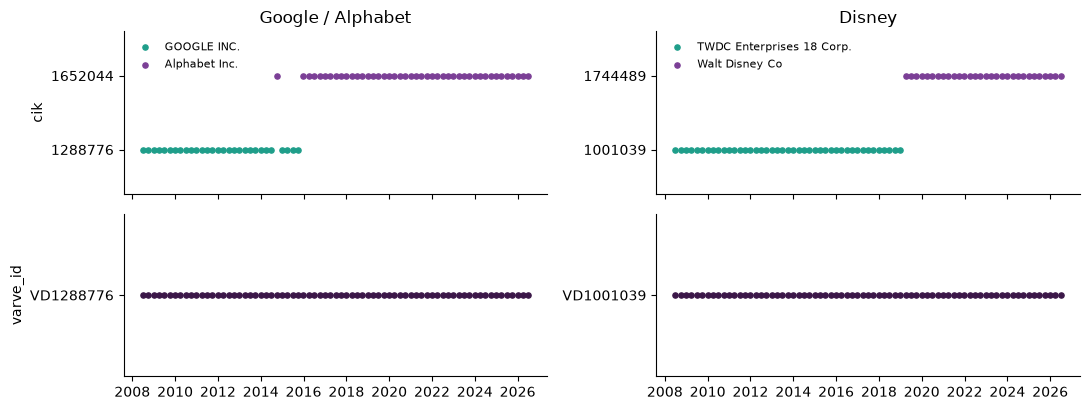

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 4.2), sharex="col")
for col, (vid, label) in enumerate([("VD1288776", "Google / Alphabet"), ("VD1001039", "Disney")]):
    s = q[(q["varve_id"] == vid) & q["lineage_primary"]].sort_values("period_end")
    ciks = list(lineage.loc[lineage["varve_id"] == vid].sort_values("seq")["cik"])
    for k, c in enumerate(ciks):
        part = s[s["cik"] == c]
        axes[0, col].scatter(part["period_end"], [str(c)] * len(part), s=14, color=["#1f9e8a", "#7b3f96"][k],
                             label=lineage.loc[lineage["cik"] == c, "name"].iloc[0])
    axes[1, col].scatter(s["period_end"], s["varve_id"], s=14, color="#3b1748")
    axes[0, col].set_title(label)
    axes[0, col].legend(loc="upper left", fontsize=8, frameon=False)
axes[0, 0].set_ylabel("cik")
axes[1, 0].set_ylabel("varve_id")
for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.6)
plt.tight_layout()
plt.show()

(The old Disney entity was renamed TWDC Enterprises 18 Corp. after the reorganization;
EDGAR shows an entity's current name. The lone Alphabet dot in 2014 is Q3 2014, which
both CIKs filed on the same day in October 2015; on a tie the newer CIK's row is the
primary one.)

## What breaks if you key on CIK

### 1. On any given date, the CIK has almost no history

Point-in-time research only uses rows already public on the date in question (the
quarterly table's `filed` is the date the whole row was public; see notebook 02).
Count the quarters of Google/Alphabet history that a backtest could see at each
quarter-end, keyed on Alphabet's CIK versus on `varve_id`:

In [6]:
goog = q[q["varve_id"] == "VD1288776"]
alphabet_cik = goog[goog["cik"] == 1652044]               # keyed on Alphabet's own CIK
company = goog[goog["lineage_primary"]]                  # keyed on varve_id

as_of = pd.date_range("2015-09-30", "2017-06-30", freq="QE")
known = pd.DataFrame({
    "as_of": as_of.date,
    "quarters_public_cik_1652044": [int((alphabet_cik["filed"] <= d).sum()) for d in as_of],
    "quarters_public_varve_id": [int((company["filed"] <= d).sum()) for d in as_of],
})
known

,as_of,quarters_public_cik_1652044,quarters_public_varve_id
0,2015-09-30,0,28
1,2015-12-31,1,30
2,2016-03-31,4,30
3,2016-06-30,5,30
4,2016-09-30,6,30
5,2016-12-31,8,31
6,2017-03-31,9,32
7,2017-06-30,11,34


Alphabet's CIK does eventually hold rows back to 2012, but only as comparatives in its
later filings, each dated when Alphabet filed it. Until then, anything that needs a
lookback (year-over-year growth needs 5 quarters, 3-year growth 13, an 8-quarter
volatility 8) is missing or has to wait for the comparatives. Keyed on `varve_id`, the
full history was public all along, because Google Inc. had filed it.

(The `varve_id` count pauses during 2016 because a quarterly row is dated by the last of
its fields to become public. Alphabet's 2016 10-Qs gave EPS only in a form the build
doesn't pick up, so those rows complete with the next year's comparatives, and its
derived Q4 2015 waits for its own Q1–Q3 2015 figures. Revenue alone was public on time:
for one field, use the `facts` table, which dates each value separately.)

### 2. A reorganization looks like a delisting

A survivorship-bias-free universe keeps companies that stop filing. Keyed on CIK,
Google Inc. "stopped filing" in October 2015 and Disney's old entity in early 2019: a backtest would
record them as exits, exactly like a bankruptcy or an acquisition. With `varve_id` they
are the same live company.

In [7]:
c = companies[companies["varve_id"].isin(["VD1288776", "VD1001039"])]
c[["cik", "varve_id", "name", "first_filed", "last_filed"]].sort_values(["varve_id", "first_filed"])

,cik,varve_id,name,first_filed,last_filed
15,1001039,VD1001039,WALT DISNEY CO/,2009-07-30,2019-02-05
26,1744489,VD1001039,WALT DISNEY CO,2019-05-08,2026-08-05
21,1288776,VD1288776,GOOGLE INC.,2009-08-04,2015-10-29
25,1652044,VD1288776,ALPHABET INC.,2015-10-29,2026-07-23


In [8]:
by_company = c.groupby("varve_id").agg(first_filed=("first_filed", "min"), last_filed=("last_filed", "max"),
                                       ciks=("cik", lambda s: ", ".join(map(str, s))))
by_company

,first_filed,last_filed,ciks
varve_id,,,
VD1001039,2009-07-30,2026-08-05,"1001039, 1744489"
VD1288776,2009-08-04,2026-07-23,"1288776, 1652044"


### 3. The new CIK repeats the old one's history, filed later

A new holding company's first annual report includes the old company's figures as
comparatives. Both CIKs then hold a row for the same quarter: the original, filed when
the number was first public, and a copy filed months or years later. Keeping both
double-counts the quarter. Keeping only the new CIK's copy dates the number later than
it really became public, and some copies are incomplete (the empty `revenue` cells
below). `lineage_primary` marks the row **filed first** for each `varve_id` and period,
so there is exactly one row per quarter, dated when it was first public.

In [9]:
dup = goog[goog.duplicated(["varve_id", "period_end"], keep=False)].sort_values(["period_end", "filed"])
dup[["period_end", "cik", "filed", "revenue", "lineage_primary"]].assign(
    period_end=lambda d: d["period_end"].dt.date, filed=lambda d: d["filed"].dt.date).head(12)

,period_end,cik,filed,revenue,lineage_primary
1494,2012-12-31,1288776,2013-01-29,1.321500e+10,True
1681,2012-12-31,1652044,2016-02-11,NaN,False
1498,2013-12-31,1288776,2015-02-09,1.685800e+10,True
1682,2013-12-31,1652044,2016-02-11,NaN,False
1501,2014-09-30,1288776,2015-10-29,1.652300e+10,False
1683,2014-09-30,1652044,2015-10-29,1.652300e+10,True
1502,2014-12-31,1288776,2015-02-09,1.810300e+10,True
1684,2014-12-31,1652044,2016-02-11,NaN,False
1503,2015-03-31,1288776,2015-04-29,1.725800e+10,True
1685,2015-03-31,1652044,2016-05-03,1.725800e+10,False


In [10]:
print(f"Google/Alphabet quarterly rows: {len(goog)}, quarters: {goog['period_end'].nunique()}, "
      f"lineage_primary rows: {int(goog['lineage_primary'].sum())}")

Google/Alphabet quarterly rows: 80, quarters: 73, lineage_primary rows: 73


## Tickers follow the company too

`ticker_history` carries `varve_id`, so a price series keyed on ticker joins to one
company even when the ticker moved between CIKs. GOOG belonged to Google Inc. until
October 2015 and to Alphabet after, under the same `varve_id`.

In [11]:
tickers[tickers["varve_id"] == "VD1288776"].sort_values("valid_from")[
    ["ticker", "cik", "varve_id", "valid_from", "valid_to", "sources"]]

,ticker,cik,varve_id,valid_from,valid_to,sources
54,GOOG,1288776,VD1288776,2006-01-04,2015-10-05,insider
61,GOOG,1652044,VD1288776,2015-10-08,2024-06-20,insider+sec_list
62,GOOGL,1652044,VD1288776,2017-02-01,2017-02-02,insider
55,GOOG,1288776,VD1288776,2017-08-28,2019-09-07,sec_list
56,GOOGL,1288776,VD1288776,2017-08-28,2019-09-07,sec_list
63,GOOGL,1652044,VD1288776,2019-10-02,NaT,insider+sec_list
64,GOOGM,1652044,VD1288776,2026-07-16,NaT,sec_list
65,GOOGN,1652044,VD1288776,2026-07-16,NaT,sec_list


Exxon is the newest case. ExxonMobil Holdings Corp (CIK 2115436) took over the XOM
listing on 1 July 2026 and has not filed financials of its own yet (`in_dataset` is
False in `company_lineage`). Its future filings will carry `varve_id` VD34088, and so do
all of Exxon Mobil Corp's quarters since 2008, so a series keyed on `varve_id` will not
break when they arrive.

In [12]:
lineage[lineage["varve_id"] == "VD34088"][["varve_id", "cik", "name", "valid_from", "valid_to", "link_evidence", "in_dataset"]]

,varve_id,cik,name,valid_from,valid_to,link_evidence,in_dataset
4,VD34088,34088,EXXON MOBIL CORP,1994-03-11,2026-06-30,NaN,True
5,VD34088,2115436,ExxonMobil Holdings Corp,2026-07-01,NaT,ticker handoff XOM,False


## Recipe

* **Group, join and sort on `varve_id`**, not `cik`, whenever you need a company's history.
* **Filter to `lineage_primary`** in `quarterly` and `annual` for one point-in-time row per
  company and period.
* **Keep `cik`** for linking back to EDGAR: it names the legal entity that filed each row.
* Every table carries `varve_id`. For a CIK from somewhere else, map it through
  `company_lineage`; a CIK that isn't there is its own chain, `"VD" + cik`:

In [13]:
def to_varve_id(cik, lineage=lineage):
    m = dict(zip(lineage["cik"], lineage["varve_id"]))
    return pd.Series(cik).map(lambda c: m.get(c, f"VD{int(c)}"))

to_varve_id([1652044, 1288776, 320193]).tolist()      # Alphabet, Google Inc., Apple

['VD1288776', 'VD1288776', 'VD320193']

What is deliberately **not** linked: a new company formed by merging two (it has two
predecessors), acquisitions, spin-offs, blank-check (SPAC) mergers, and a name or ticker
passing to a different company (Overstock taking the Bed Bath & Beyond name and BBBY;
see notebook 03). The methodology guide documents the linking rules and the cases they
leave out.